# Insurance Claims & Portfolio Risk Dashboard

| Column | Meaning |
|---|---|
| IDpol |  policy ID |
| ClaimNb | number of claims during exposure |
| Exposure | exposure period in years |
| VehPower | vehicle power |
| VehAge | vehicle age |
| DrivAge | driver age |
| BonusMalus | bonus/malus score |
| VehBrand | vehicle-brand category |
| VehGas | fuel type|
| Area | density category from rural to urban |
| Density | population density |
| Region | policy region |
| ClaimAmount | claim cost in the severity table |

## Import Libraries

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df_freq = pd.read_csv("freMTPL2freq.csv")
df_freq.head()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


In [28]:
df_sev = pd.read_csv("freMTPL2sev.csv")
df_sev.head()

,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [29]:
print(f'Rows: {df_freq.shape[0]}')
print(f'Columns: {df_freq.shape[1]}')

Rows: 678013
Columns: 12


In [30]:
df_freq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  object 
 8   VehGas      678013 non-null  object 
 9   Area        678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 62.1+ MB


In [31]:
df_freq.describe().round(3)

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000
mean,2621856.921,0.053,0.529,6.455,7.044,45.499,59.762,1792.422
std,1641782.753,0.240,0.364,2.051,5.666,14.137,15.637,3958.647
min,1.000,0.000,0.003,4.000,0.000,18.000,50.000,1.000
25%,1157951.000,0.000,0.180,5.000,2.000,34.000,50.000,92.000
50%,2272152.000,0.000,0.490,6.000,6.000,44.000,50.000,393.000
75%,4046274.000,0.000,0.990,7.000,11.000,55.000,64.000,1658.000
max,6114330.000,16.000,2.010,15.000,100.000,100.000,230.000,27000.000


In [32]:
overview = pd.DataFrame({
    "type": df_freq.dtypes,
    "unique values": df_freq.nunique(),
    "missing": df_freq.isna().sum(),
    "example": df_freq.iloc[10]
})
overview

,type,unique values,missing,example
IDpol,float64,678013,0,25.0
ClaimNb,int64,11,0,1
Exposure,float64,181,0,0.75
VehPower,int64,12,0,7
VehAge,int64,78,0,0
DrivAge,int64,83,0,41
BonusMalus,int64,115,0,50
VehBrand,object,11,0,B12
VehGas,object,2,0,Diesel
Area,object,6,0,B


In [50]:
df_sev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol        26639 non-null  int64  
 1   ClaimAmount  26639 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 416.4 KB


In [52]:
df_sev.isna().sum()

IDpol          0
ClaimAmount    0
dtype: int64

In [61]:
df_sev.duplicated().sum()

255

In [48]:
d_change = ["ClaimNb", "VehPower", "VehAge", "DrivAge"]
df_freq[d_change] = df_freq[d_change].astype("UInt16")

In [49]:
df_freq["IDpol"] = df_freq["IDpol"].astype("UInt64")

### There are 28688 duplicate values but as policy id is different I don't drop duplicates

In [43]:
duplicate_count = df_freq.drop(columns=['IDpol']).duplicated().sum()
duplicate_count

28688

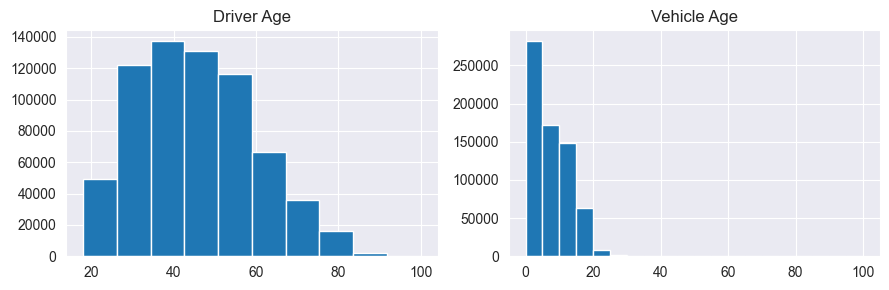

In [35]:
plt.figure(figsize=(9,3))
plt.subplot(1,2,1)
plt.hist(df_freq["DrivAge"])
plt.title("Driver Age")

plt.subplot(1,2,2)
plt.hist(df_freq["VehAge"], bins=20)
plt.title("Vehicle Age")
plt.tight_layout()
plt.show()

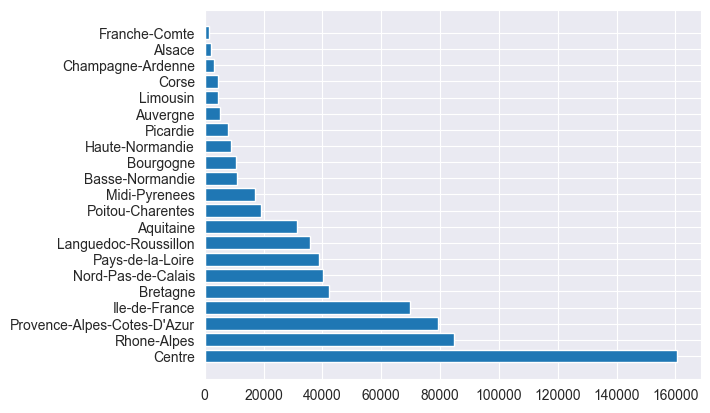

In [36]:
region = df_freq["Region"].value_counts()
plt.barh(region.index, region)
plt.show()

In [37]:
unique_list = ['ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge',
       'BonusMalus', 'VehBrand', 'VehGas', 'Area', 'Region']

for i in unique_list:
    print(f'{i}\n{df_freq[i].unique().tolist()}')
    print("-" * 50)

ClaimNb
[1, 2, 4, 3, 11, 0, 5, 6, 8, 16, 9]
--------------------------------------------------
Exposure
[0.1, 0.77, 0.75, 0.09, 0.84, 0.52, 0.45, 0.27, 0.71, 0.15, 0.87, 0.81, 0.05, 0.76, 0.34, 0.74, 0.03, 0.06, 0.55, 0.19, 0.01, 0.79, 0.04, 0.8, 0.07, 0.39, 0.47, 0.69, 0.16, 0.12, 0.41, 0.46, 0.82, 0.11, 0.08, 0.02, 0.72, 0.14, 0.5, 0.92, 0.9, 0.78, 0.83, 0.67, 0.13, 0.59, 0.21, 0.65, 0.42, 0.85, 0.73, 0.23, 0.48, 0.37, 0.86, 0.17, 0.24, 0.63, 0.51, 0.64, 0.66, 0.18, 0.31, 0.35, 0.25, 0.62, 0.22, 0.7, 0.58, 0.28, 0.61, 0.53, 0.2, 0.008196721, 0.005464481, 0.43, 0.33, 0.57, 0.36, 0.56, 0.3, 0.6, 0.68, 0.97, 0.54, 0.44, 0.49, 0.29, 0.32, 0.26, 0.00273224, 0.96, 0.98, 0.88, 0.4, 0.89, 0.38, 0.95, 0.94, 0.93, 0.91, 1.0, 0.99, 0.005479452, 0.002739726, 0.008219178, 1.99, 1.17, 1.12, 1.48, 1.5, 1.53, 1.01, 1.03, 1.09, 1.56, 1.07, 1.43, 1.34, 1.46, 1.37, 1.41, 1.05, 1.04, 1.02, 1.08, 1.06, 1.15, 1.13, 1.2, 1.11, 1.14, 1.16, 1.18, 1.22, 1.23, 1.26, 1.1, 1.3, 1.38, 1.29, 1.25, 1.32, 1.45, 1.21

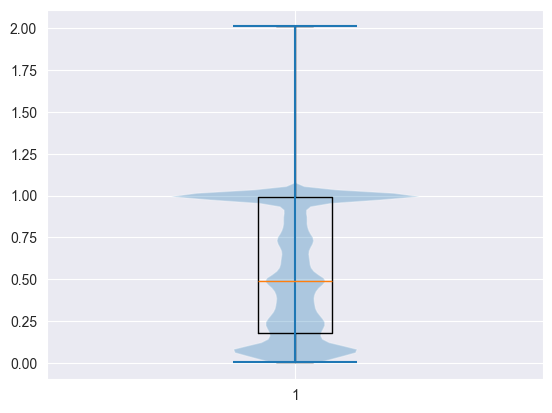

In [38]:
plt.boxplot(df_freq["Exposure"])
plt.violinplot(df_freq["Exposure"])
plt.show()

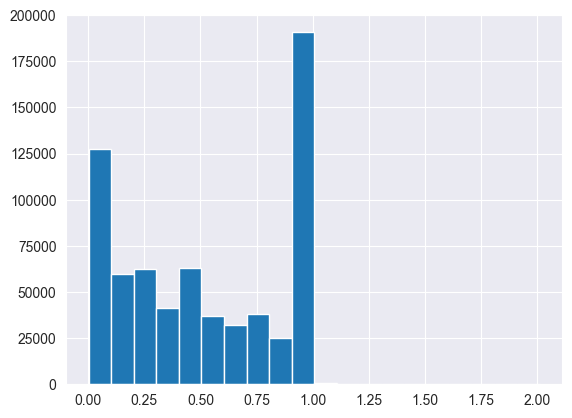

In [39]:
plt.hist(df_freq["Exposure"], bins= 20)
plt.show()

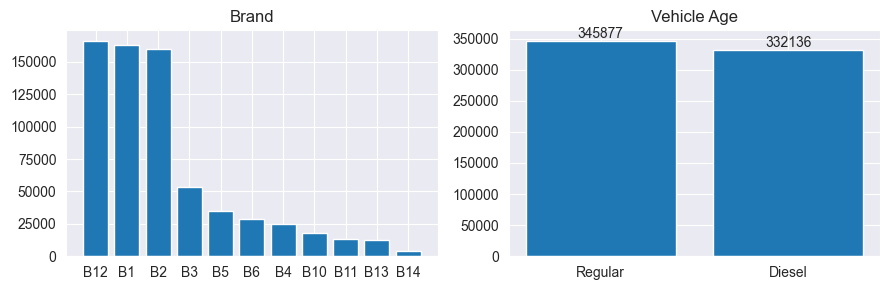

In [44]:
plt.figure(figsize=(9,3))
plt.subplot(1,2,1)
brand = df_freq["VehBrand"].value_counts()
plt.bar(brand.index, brand )
plt.title("Brand")

plt.subplot(1,2,2)
gas = df_freq["VehGas"].value_counts()
g = plt.bar(gas.index, gas)
plt.bar_label(g)
plt.title("Vehicle Age")
plt.tight_layout()
plt.show()